In [1]:
import json
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA = Path("data")
manifest = json.loads((DATA / "manifest.json").read_text())
SESSIONS = manifest["sessions"]                          # ['s01', ..., 's24']
SYMBOLS = [s["symbol"] for s in manifest["symbols"]]     # ['HPPO', 'BNKY', 'CRRT', 'BRRY']
BATCHES_PER_MIN = 60_000 // manifest["batch_ms"]         # 120


In [2]:
def load_tops(name):
    """Top of book for one session, plus mid, spread and microprice (cents)."""
    df = pd.read_csv(DATA / f"{name}.top.csv")   # blank cell -> NaN: an empty side, never zero
    df["session"] = name
    df["mid"] = (df["bid_px"] + df["ask_px"]) / 2
    df["spread"] = df["ask_px"] - df["bid_px"]
    df["microprice"] = (df["bid_px"] * df["ask_qty"] + df["ask_px"] * df["bid_qty"]) / (df["bid_qty"] + df["ask_qty"])
    df["mid_ffill"] = df.groupby("symbol")["mid"].ffill()   # one-sided book: keep the last mid
    return df

def load_trades(name):
    """Every execution, with signed qty: + buyer-initiated, - seller-initiated."""
    df = pd.read_csv(DATA / f"{name}.trades.csv")
    df["session"] = name
    df["signed_qty"] = df["qty"].where(df["aggressor"] == "BUY", -df["qty"])
    return df

tops = pd.concat([load_tops(n) for n in SESSIONS], ignore_index=True)
trades = pd.concat([load_trades(n) for n in SESSIONS], ignore_index=True)
tops["minute"] = tops["batch"] / BATCHES_PER_MIN
trades["minute"] = trades["batch"] / BATCHES_PER_MIN

print(f"tops {len(tops):,} rows, trades {len(trades):,} rows")
print(tops.groupby("session").size().unique(), "rows per session")
print(tops.assign(one_sided=tops["mid"].isna()).groupby("symbol")["one_sided"].mean())


tops 518,400 rows, trades 1,271,552 rows
[21600] rows per session
symbol
BNKY    0.000000
BRRY    0.008819
CRRT    0.002006
HPPO    0.000648
Name: one_sided, dtype: float64


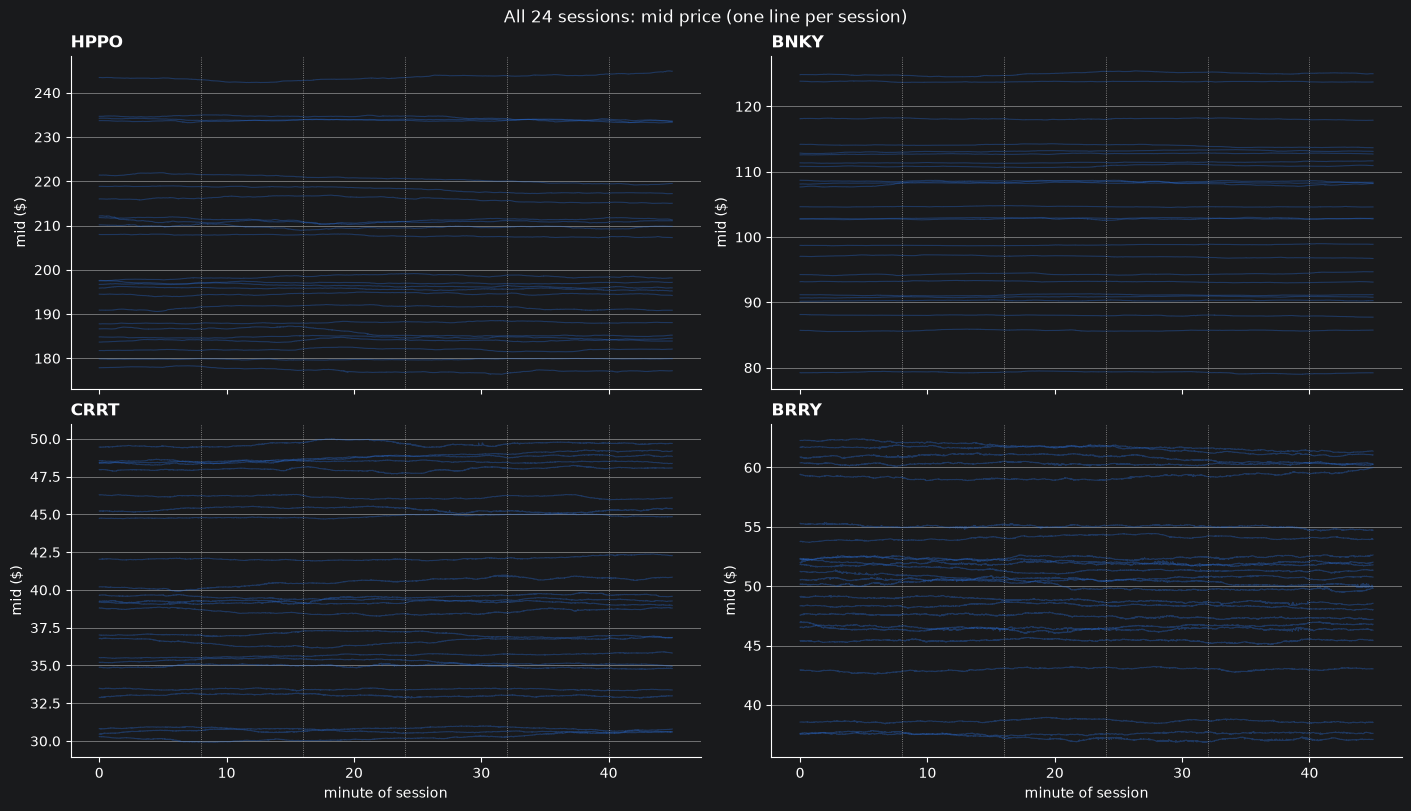

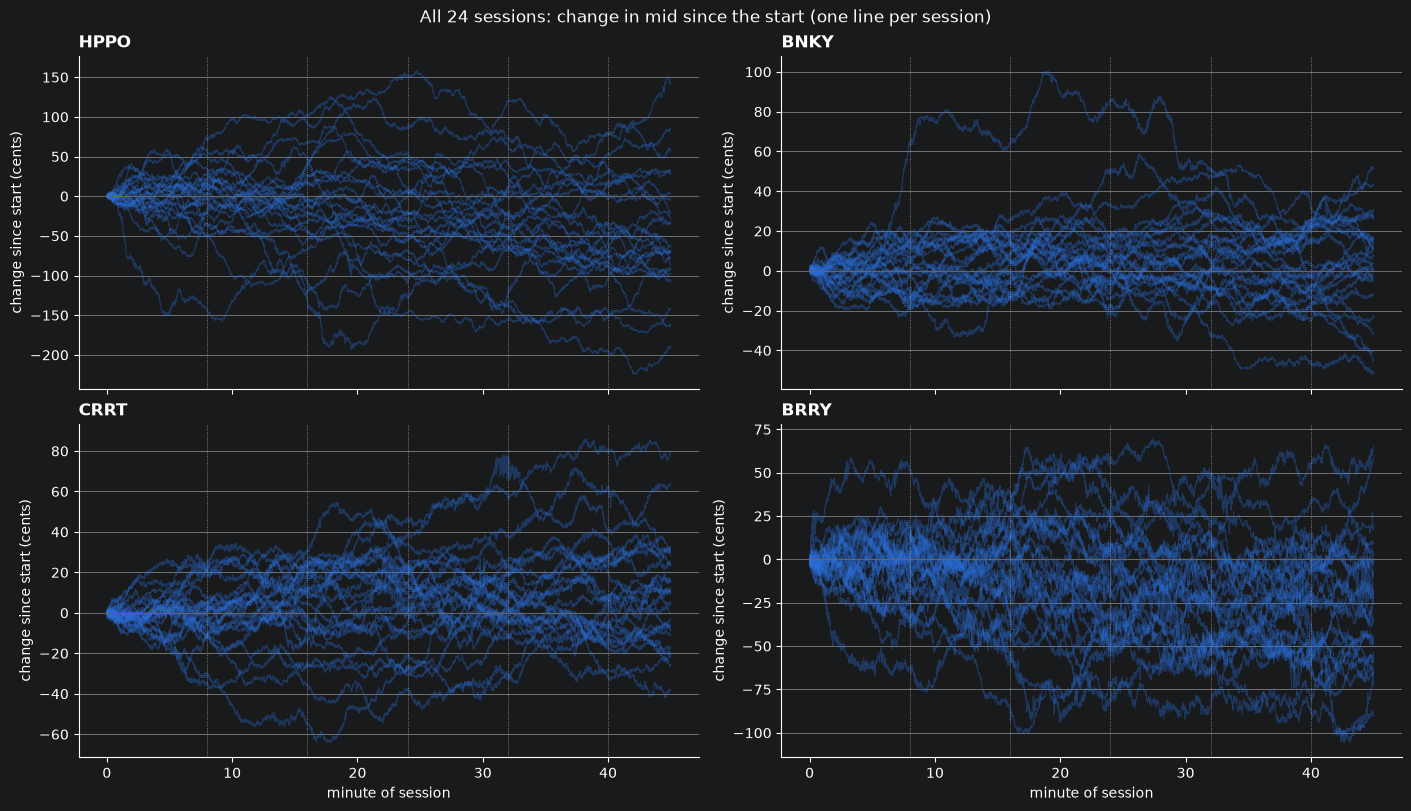

In [3]:
def plot_sessions(tops, relative=False):
    fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True, layout="constrained")
    for ax, symbol in zip(axes.flat, SYMBOLS):
        sym = tops[tops["symbol"] == symbol]
        for _, s in sym.groupby("session"):
            y = s["mid_ffill"] - s["mid_ffill"].iloc[0] if relative else s["mid_ffill"] / 100
            ax.plot(s["minute"], y, color="#2a6fdb", linewidth=0.8, alpha=0.35)
        for day_end in range(8, 41, 8):
            ax.axvline(day_end, color="#999999", linewidth=0.6, linestyle=":")
        if relative:
            ax.axhline(0, color="#666666", linewidth=0.8)
        ax.set_title(symbol, loc="left", fontweight="bold")
        ax.set_ylabel("change since start (cents)" if relative else "mid ($)")
        ax.grid(axis="y", color="#e5e5e5", linewidth=0.6)
        ax.spines[["top", "right"]].set_visible(False)
    for ax in axes[1]:
        ax.set_xlabel("minute of session")
    kind = "change in mid since the start" if relative else "mid price"
    fig.suptitle(f"All {tops['session'].nunique()} sessions: {kind} (one line per session)")
    return fig

plot_sessions(tops, relative=False);
plot_sessions(tops, relative=True);


In [4]:
HORIZON = 120  # 60 s ahead: the scoring horizon

wide = (tops.set_index(["session", "batch", "symbol"])
            [["mid", "mid_ffill", "microprice", "bid_qty", "ask_qty"]]
            .unstack("symbol").sort_index())
mid = wide["mid_ffill"]                                   # cents
imb = (wide["microprice"] - wide["mid"]).fillna(0)        # book imbalance, cents
flow = (trades.groupby(["session", "batch", "symbol"])["signed_qty"].sum()
              .unstack("symbol").reindex(index=wide.index, columns=SYMBOLS).fillna(0))

def by_session(df):
    return df.groupby(level="session")

# Typical size at the best price, as a running average (only uses the past), to scale flow across sessions
depth = by_session((wide["bid_qty"] + wide["ask_qty"]) / 2).transform(lambda d: d.ffill().ewm(span=600).mean())

def past_change(df, k):   # change over the last k batches
    return df - by_session(df).shift(k)

def rolling_sum(df, k):   # sum over the last k batches
    return by_session(df).transform(lambda d: d.rolling(k, min_periods=1).sum())

gap = mid["HPPO"] - mid["BNKY"] - 2 * mid["BRRY"]          # ETF minus its basket, cents
flow_k = {k: rolling_sum(flow, k) / depth for k in (5, 20, 60)}
ret_k = {k: past_change(mid, k) for k in (2, 10, 60)}

def future_change(sym, horizon=HORIZON):   # what we predict: mid `horizon` batches later minus now
    return by_session(mid[sym]).shift(-horizon) - mid[sym]


In [5]:
HOLDOUT = ["s19", "s20", "s21", "s22", "s23", "s24"]          # set to [] for the final competition model
TRAIN_SESSIONS = [s for s in SESSIONS if s not in HOLDOUT]

def features_for(sym):
    f = pd.DataFrame(index=mid.index)
    f["imbalance"] = imb[sym]
    for k, v in flow_k.items():
        f[f"flow_{k}"] = v[sym]
    for k, v in ret_k.items():
        f[f"ret_{k}"] = v[sym]
    f["etf_gap"] = gap
    if sym != "HPPO":                     # HPPO leads: use it in the others' models
        f["hppo_ret_10"] = ret_k[10]["HPPO"]
        f["hppo_flow_20"] = flow_k[20]["HPPO"]
    return f

def dataset(sym, horizon=HORIZON, every=5, sessions=TRAIN_SESSIONS):
    """X, y, groups for one symbol, from `sessions` only. Every 5th batch; 1%/99% clipped."""
    d = features_for(sym).join(future_change(sym, horizon).rename("y")).dropna()
    d = d[d.index.get_level_values("session").isin(sessions)]   # before clipping: no holdout leaks in
    d = d[d.index.get_level_values("batch") % every == 0]
    d = d.clip(d.quantile(0.01), d.quantile(0.99), axis=1)
    return d.drop(columns="y"), d["y"], d.index.get_level_values("session")

print(f"training on {len(TRAIN_SESSIONS)} sessions, holding out {HOLDOUT or 'none'}")
X, y, groups = dataset("BRRY")
print(X.shape)
X.describe().T.round(2)


training on 18 sessions, holding out ['s19', 's20', 's21', 's22', 's23', 's24']
(18792, 10)


,count,mean,std,min,25%,50%,75%,max
imbalance,18792.0,-0.04,2.43,-5.95,-1.57,0.00,1.50,5.90
flow_5,18792.0,-0.02,3.08,-10.09,-1.44,-0.03,1.35,10.83
flow_20,18792.0,-0.09,9.69,-32.83,-3.71,-0.15,3.28,36.36
flow_60,18792.0,-0.31,25.02,-82.99,-8.27,-0.60,6.73,91.81
ret_2,18792.0,-0.00,1.43,-4.50,-0.50,0.00,0.50,4.50
ret_10,18792.0,-0.06,2.24,-6.00,-1.50,0.00,1.50,6.00
ret_60,18792.0,-0.35,5.46,-14.00,-4.00,0.00,3.50,12.50
etf_gap,18792.0,-0.11,11.74,-23.00,-10.00,-0.50,9.50,23.50
hppo_ret_10,18792.0,-0.09,2.09,-5.50,-1.50,0.00,1.50,5.00
hppo_flow_20,18792.0,-0.06,3.19,-8.84,-2.00,-0.04,1.88,8.75


In [6]:
from sklearn.linear_model import RidgeCV
from sklearn.metrics import r2_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ALPHAS = [0.1, 1, 10, 100, 1_000, 10_000]

def make_model():
    return make_pipeline(StandardScaler(), RidgeCV(alphas=ALPHAS))

def evaluate(sym, horizon=HORIZON, n_splits=6):
    X, y, groups = dataset(sym, horizon)
    oof = pd.Series(np.nan, index=y.index)     # out-of-fold: each row predicted by a model that never saw its session
    fold_r2 = []
    for train, test in GroupKFold(n_splits=n_splits).split(X, y, groups):
        m = make_model().fit(X.iloc[train], y.iloc[train])
        oof.iloc[test] = m.predict(X.iloc[test])
        fold_r2.append(r2_score(y.iloc[test], oof.iloc[test]))
    return {"X": X, "y": y, "oof": oof, "fold_r2": np.array(fold_r2), "model": make_model().fit(X, y)}

results = {}
for sym in SYMBOLS:
    r = results[sym] = evaluate(sym)
    print(f"{sym}: out-of-sample R² {r['fold_r2'].mean():+.4f}   folds {np.round(r['fold_r2'], 3)}   alpha {r['model'][-1].alpha_}")


HPPO: out-of-sample R² +0.1256   folds [0.13  0.136 0.081 0.138 0.102 0.166]   alpha 100.0
BNKY: out-of-sample R² +0.0528   folds [0.032 0.031 0.038 0.047 0.072 0.098]   alpha 100.0
CRRT: out-of-sample R² +0.1060   folds [0.134 0.122 0.012 0.11  0.108 0.151]   alpha 100.0
BRRY: out-of-sample R² +0.2372   folds [0.231 0.243 0.23  0.251 0.291 0.177]   alpha 10.0


In [7]:
MODELS_DIR = Path("strategies/models")
MODELS_DIR.mkdir(exist_ok=True)

FOLDS = {f"fold{i + 1}": SESSIONS[6 * i : 6 * (i + 1)] for i in range(4)}   # fold1 = s01-s06, ..., fold4 = s19-s24
FOLD_OF = {s: fold for fold, members in FOLDS.items() for s in members}

# Five models: each "excl_foldN" is trained on the 18 sessions outside fold N; "all24" on everything.
MODEL_SETS = {f"excl_{fold}": [s for s in SESSIONS if s not in members] for fold, members in FOLDS.items()}
MODEL_SETS["all24"] = list(SESSIONS)

def fit_and_export(train_sessions, path):
    """Fit one ridge model per symbol on `train_sessions` and write it in the format theo_mm.py loads."""
    out = {"horizon": HORIZON, "trained_on": train_sessions, "symbols": {}}
    for sym in SYMBOLS:
        X, y, _ = dataset(sym, sessions=train_sessions)
        model = make_model().fit(X, y)
        scaler, ridge = model[0], model[-1]
        w = ridge.coef_ / scaler.scale_                      # cents of predicted move per unit of feature
        out["symbols"][sym] = {
            "features": list(X.columns),
            "weights": [float(v) for v in w],
            "intercept": float(-(w * scaler.mean_).sum()),   # centred features, no drift term
            "clip_lo": [float(v) for v in X.min()],          # X was clipped at 1%/99%: these are the bounds
            "clip_hi": [float(v) for v in X.max()],
        }
    path.write_text(json.dumps(out, indent=2))

MODEL_PATHS = {}
for name, train in MODEL_SETS.items():
    MODEL_PATHS[name] = (MODELS_DIR / f"theo_{name}.json").resolve()
    fit_and_export(train, MODEL_PATHS[name])
    print(f"{name:11s} trained on {len(train)} sessions -> {MODEL_PATHS[name].name}")


excl_fold1  trained on 18 sessions -> theo_excl_fold1.json
excl_fold2  trained on 18 sessions -> theo_excl_fold2.json
excl_fold3  trained on 18 sessions -> theo_excl_fold3.json
excl_fold4  trained on 18 sessions -> theo_excl_fold4.json
all24       trained on 24 sessions -> theo_all24.json


In [8]:
from joblib import Parallel, delayed

def backtest_one(session, model_name, model_path, data_dir, strategies_dir, defaults):
    """One backtest of TheoMM with one model file and some panel defaults changed. Runs in a worker process."""
    import dataclasses, logging, sys
    if strategies_dir not in sys.path:
        sys.path.insert(0, strategies_dir)
    from pathlib import Path
    from theo_mm import TheoMM
    from pqt_client.backtest_v2 import load_session
    from pqt_client.v2 import backtest_strategy

    logging.getLogger("pqt").setLevel(logging.WARNING)
    names = {p.name for p in TheoMM.MODEL_PARAMS}
    unknown = set(defaults) - names
    if unknown:
        raise ValueError(f"unknown parameters {sorted(unknown)}; the panel has {sorted(names)}")
    params = tuple(dataclasses.replace(p, default=defaults.get(p.name, p.default)) for p in TheoMM.MODEL_PARAMS)
    cls = type("Variant", (TheoMM,), {"MODEL_PARAMS": params, "MODEL_PATH": Path(model_path)})
    strat = cls()
    backtest_strategy(load_session(data_dir, session), strat)
    row = {"session": session, "model": model_name}
    row.update({s: v / 100 for s, v in strat.markouts().items()})    # dollars
    row["total"] = sum(v for k, v in row.items() if k in strat.model)
    return row

def run_cv(n_jobs=-1, **defaults):
    """Backtest every session with all five models (120 backtests). Returns one row per (session, model)."""
    jobs = [(s, name) for s in SESSIONS for name in MODEL_PATHS]
    rows = Parallel(n_jobs=n_jobs)(
        delayed(backtest_one)(s, name, str(MODEL_PATHS[name]), str(DATA.resolve()),
                              str(Path("strategies").resolve()), defaults)
        for s, name in jobs
    )
    df = pd.DataFrame(rows)
    df["fold"] = df["session"].map(FOLD_OF)
    df["held_out"] = df["model"] == "excl_" + df["fold"]    # True: this model never saw this session
    return df

def cv_tables(df):
    """Per-session totals for each model, plus the honest out-of-sample column and a per-symbol summary."""
    models = list(MODEL_PATHS)
    totals = df.pivot(index="session", columns="model", values="total")[models].round(0)
    excl = [m for m in models if m.startswith("excl_")]
    totals.insert(0, "fold", totals.index.map(FOLD_OF))
    totals.insert(1, "held_out_by", "excl_" + totals["fold"])
    totals["out_of_sample"] = [totals.loc[s, "excl_" + FOLD_OF[s]] for s in totals.index]
    totals["in_sample_avg"] = [totals.loc[s, [m for m in excl if m != "excl_" + FOLD_OF[s]]].mean().round(0)
                               for s in totals.index]
    by_symbol = pd.DataFrame({
        "out_of_sample": df[df["held_out"]][SYMBOLS + ["total"]].sum(),
        "all24 (in-sample)": df[df["model"] == "all24"][SYMBOLS + ["total"]].sum(),
    }).T.round(0)
    oos = totals["out_of_sample"]
    print(f"out-of-sample total over 24 sessions: ${oos.sum():,.0f}  (mean ${oos.mean():,.0f}/session, "
          f"{(oos > 0).sum()}/24 sessions positive, worst ${oos.min():,.0f})")
    print(f"all24 model (in-sample everywhere):   ${totals['all24'].sum():,.0f}")
    return totals, by_symbol

def run_oos(n_jobs=-1, **defaults):
    """Faster, for tuning: each session only with the model that never saw it (24 backtests, not 120)."""
    rows = Parallel(n_jobs=n_jobs)(
        delayed(backtest_one)(s, "excl_" + FOLD_OF[s], str(MODEL_PATHS["excl_" + FOLD_OF[s]]),
                              str(DATA.resolve()), str(Path("strategies").resolve()), defaults)
        for s in SESSIONS
    )
    table = pd.DataFrame(rows).set_index("session")[SYMBOLS + ["total"]]
    table.loc["sum"] = table.sum()
    print(f"out-of-sample total ${table.loc['sum', 'total']:,.0f}, "
          f"{(table['total'].drop('sum') > 0).sum()}/24 sessions positive")
    return table.round(0)


In [9]:
cv = run_cv()                          # all 5 models x 24 sessions, about 75 s
totals, by_symbol = cv_tables(cv)
totals


out-of-sample total over 24 sessions: $98,635  (mean $4,110/session, 24/24 sessions positive, worst $2,580)
all24 model (in-sample everywhere):   $99,039


model,fold,held_out_by,excl_fold1,excl_fold2,excl_fold3,excl_fold4,all24,out_of_sample,in_sample_avg
session,,,,,,,,,
s01,fold1,excl_fold1,2580.0,2695.0,2675.0,2648.0,2670.0,2580.0,2673.0
s02,fold1,excl_fold1,5232.0,5364.0,5331.0,5179.0,5276.0,5232.0,5291.0
s03,fold1,excl_fold1,3383.0,3467.0,3446.0,3418.0,3426.0,3383.0,3444.0
s04,fold1,excl_fold1,2939.0,2998.0,2984.0,2935.0,2975.0,2939.0,2972.0
s05,fold1,excl_fold1,2998.0,2927.0,3012.0,2944.0,2930.0,2998.0,2961.0
s06,fold1,excl_fold1,4569.0,4686.0,4637.0,4570.0,4589.0,4569.0,4631.0
s07,fold2,excl_fold2,5656.0,5879.0,5863.0,5787.0,5804.0,5879.0,5769.0
s08,fold2,excl_fold2,2988.0,3059.0,3147.0,3057.0,3055.0,3059.0,3064.0
s09,fold2,excl_fold2,4215.0,4363.0,4354.0,4276.0,4347.0,4363.0,4282.0


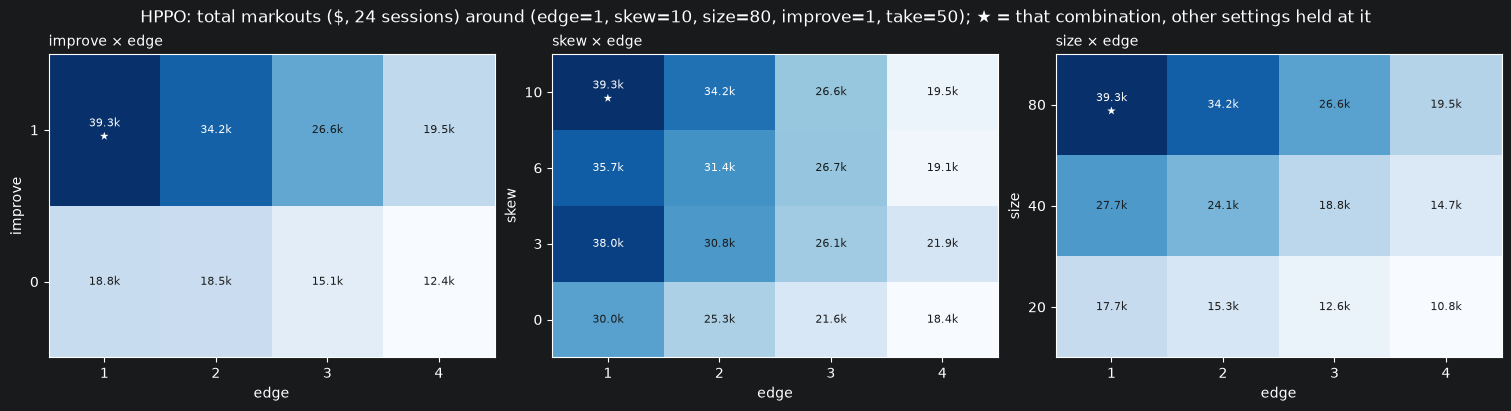

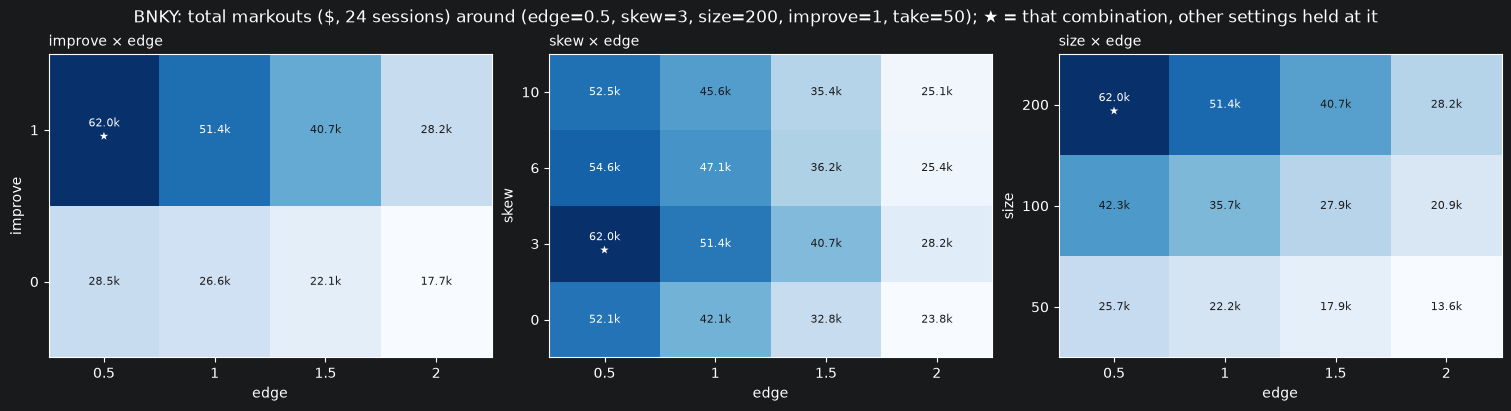

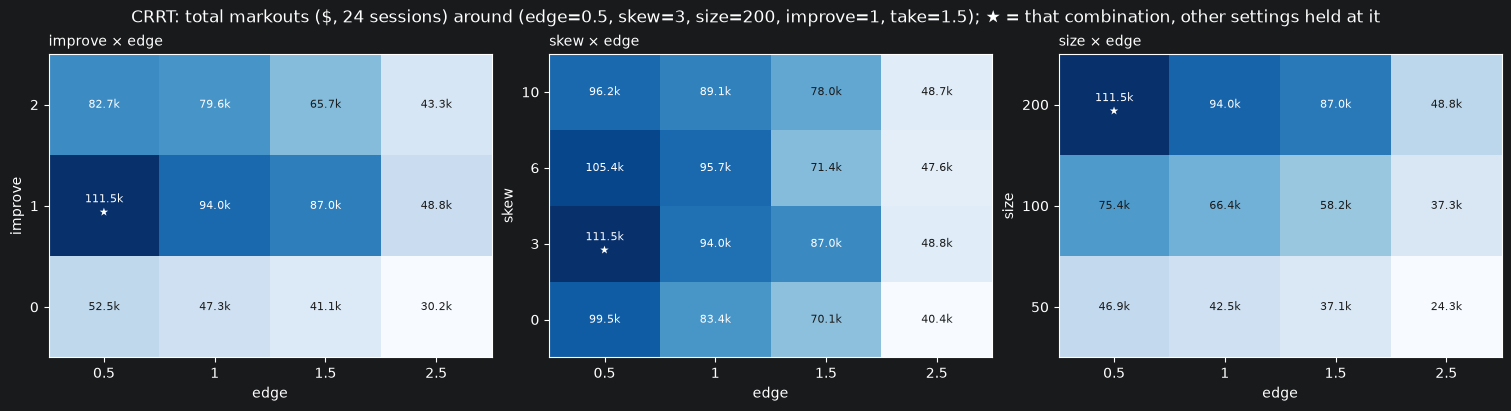

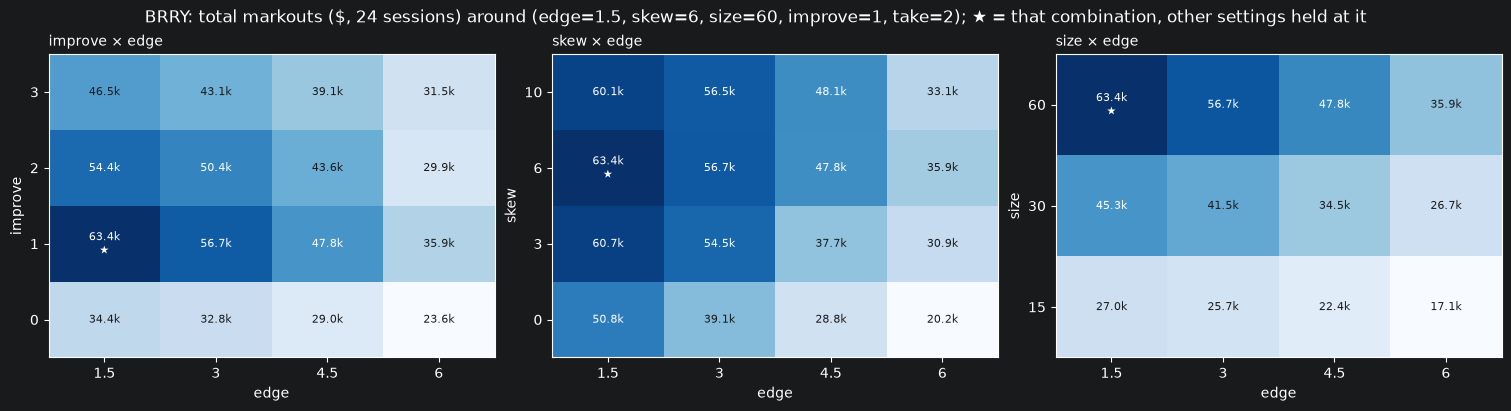

In [10]:
from matplotlib.colors import TwoSlopeNorm

GRID_CSV = Path("research/grid_results.csv")
SETTINGS = ["edge", "skew", "size", "improve", "take"]

def combo_totals(sym, path=GRID_CSV):
    """Total markouts over all sessions for every combination of one symbol's settings."""
    df = pd.read_csv(path)
    keys = [f"{k}_{sym}" for k in SETTINGS]
    per_session = df.groupby(keys + ["session"])[f"mk_{sym}"].mean()    # average repeated samples
    totals = per_session.groupby(level=keys).sum()
    totals.index = totals.index.set_names(SETTINGS)
    totals.attrs["n_sessions"] = df["session"].nunique()
    return totals

def dark_cell(n, diverging):
    """Whether a cell's colour is dark enough to need white text (both ends of RdBu are dark)."""
    return abs(n - 0.5) > 0.3 if diverging else n > 0.6

def heat_slice(ax, totals, x, y, at):
    """Heat map of total over settings x and y, with the other settings fixed at `at`."""
    others = [k for k in SETTINGS if k not in (x, y)]
    sl = totals.xs(tuple(at[k] for k in others), level=others).unstack(x)
    sl = sl.sort_index(ascending=False)                      # largest y at the top
    lo, hi = np.nanmin(sl.values), np.nanmax(sl.values)
    diverging = lo < 0 < hi
    if diverging:     # losses and gains: diverging, centred on $0 (red = loss, blue = gain)
        im = ax.imshow(sl.values, cmap="RdBu", norm=TwoSlopeNorm(0, lo, hi), aspect="auto")
    else:             # all one sign: one hue, darker = more
        im = ax.imshow(sl.values, cmap="Blues", aspect="auto")
    ax.set_xticks(range(sl.shape[1]), [f"{v:g}" for v in sl.columns])
    ax.set_yticks(range(sl.shape[0]), [f"{v:g}" for v in sl.index])
    ax.set_xlabel(x); ax.set_ylabel(y)
    for i in range(sl.shape[0]):
        for j in range(sl.shape[1]):
            v = sl.values[i, j]
            if np.isfinite(v):
                best = sl.index[i] == at[y] and sl.columns[j] == at[x]
                ax.text(j, i, f"{v / 1000:.1f}k" + ("\n★" if best else ""), ha="center", va="center", fontsize=8,
                        color="white" if dark_cell(im.norm(v), diverging) else "#1a1a1a")
    ax.set_title(f"{y} × {x}", loc="left", fontsize=10)
    return im

def plot_heatmaps(sym, pairs=(("edge", "improve"), ("edge", "skew"), ("edge", "size")), at=None):
    """Slices around `at` (default: the best combination). Pass at=dict(edge=..., skew=..., ...) to look elsewhere."""
    totals = combo_totals(sym)
    at = at or dict(zip(SETTINGS, totals.idxmax()))
    fig, axes = plt.subplots(1, len(pairs), figsize=(5 * len(pairs), 4), layout="constrained")
    for ax, (x, y) in zip(np.atleast_1d(axes), pairs):
        heat_slice(ax, totals, x, y, at)
    fixed = ", ".join(f"{k}={v:g}" for k, v in at.items())
    fig.suptitle(f"{sym}: total markouts ($, {totals.attrs['n_sessions']} sessions) around ({fixed}); "
                 "★ = that combination, other settings held at it")
    return fig

for sym in SYMBOLS:
    plot_heatmaps(sym)


In [11]:
LIVE_MODEL = Path("strategies/theo_model.json")
fit_and_export(list(SESSIONS), LIVE_MODEL)       # all 24 sessions

check = json.loads(LIVE_MODEL.read_text())
print(f"{LIVE_MODEL}: trained on {len(check['trained_on'])} sessions, symbols {list(check['symbols'])}")
assert len(check["trained_on"]) == 24, "not the full model!"


strategies/theo_model.json: trained on 24 sessions, symbols ['HPPO', 'BNKY', 'CRRT', 'BRRY']
